# DBScan. Тюков Даниил

**Данные:** экономические условия в 48 городах мира в 1991 году (отдел экономических исследований банка UBS, Швейцария).

| Переменная | Описание |
|---|---|
| `City` | Название города |
| `Work` | Взвешенное среднее число рабочих часов в год по 12 профессиям |
| `Price` | Индекс цен 112 товаров и услуг, включая аренду жилья |
| `Salary` | Индекс зарплаты за час работы по 12 профессиям после налогов |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from itertools import combinations

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

## 1. Загрузка и очистка данных

In [2]:
df_raw = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",")
df_raw.head()

,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5


In [3]:
df_raw.shape

(48, 4)

In [3]:
print("Пропуски по признакам:")
print(df_raw.isna().sum())
df_raw[df_raw["Work"] < 0]

Пропуски по признакам:
City      0
Work      0
Price     0
Salary    0
dtype: int64


,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


У Каира и Джакарты нет данных о рабочих часах и зарплате. Удалим эти два города

In [4]:
df = df_raw[df_raw["Work"] > 0]
cities = df["City"].tolist()
X_raw = df[["Work", "Price", "Salary"]]
X_raw.head()

,Work,Price,Salary
0,1714,65.6,49.0
1,1792,53.8,30.4
2,2152,37.9,11.5
3,2052,30.3,5.3
4,1708,73.8,50.5


## 2. Описательные статистики

In [6]:
X_raw.describe()

,Work,Price,Salary
count,46.000000,46.000000,46.000000
mean,1879.913043,70.100000,39.545652
std,174.342552,21.389177,24.757703
min,1583.000000,30.300000,2.700000
25%,1745.250000,51.775000,14.375000
50%,1849.000000,70.950000,43.650000
75%,1976.250000,81.900000,59.700000
max,2375.000000,115.500000,100.000000


### Ящики с усами

Строим отдельный ящик с усами для каждого признака

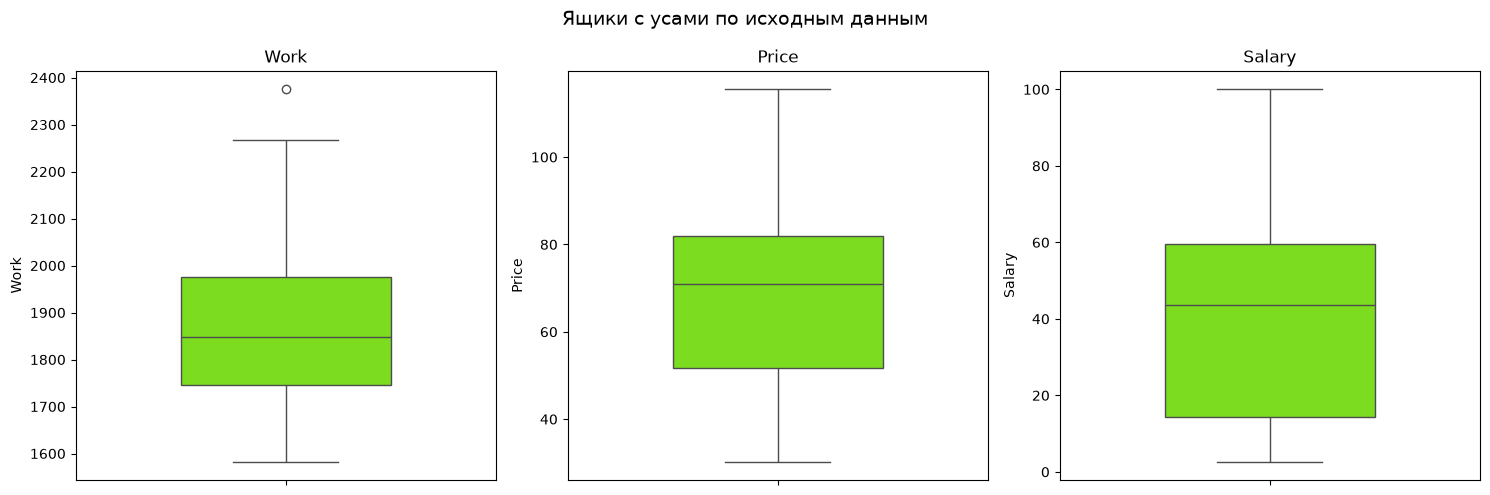

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
features = ["Work", "Price", "Salary"]
for ax, f in zip(axes, features):
    sns.boxplot(y=X_raw[f], ax=ax, color="lawngreen", width=0.5)
    ax.set_title(f)

fig.suptitle("Ящики с усами по исходным данным", fontsize=14)
plt.tight_layout()
plt.show()

In [10]:
df_raw.loc[X_raw["Work"].idxmax()]

City      Hong_Kong
Work           2375
Price          63.8
Salary         27.8
Name: 15, dtype: object

Единственный выброс — **Гонконг** по числу рабочих часов (2375 в год). Остальные значения в порядке

### Корреляции

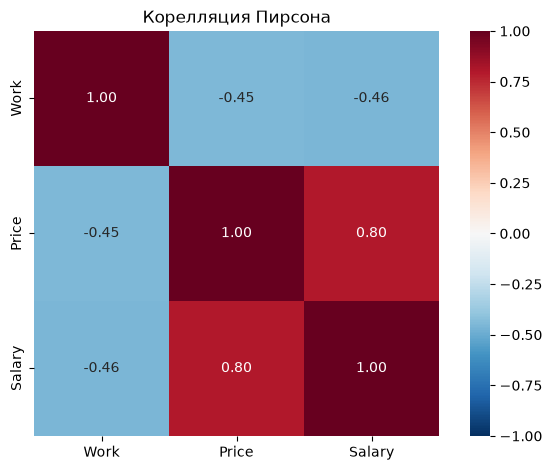

In [11]:
sns.heatmap(X_raw.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Корелляция Пирсона")
plt.tight_layout()
plt.show()

**Наблюдения:**
- Цены и зарплаты сильно связаны: r = 0,80. Где высокие цены, там больше платят.
- Рабочие часы связаны с ними обратно (r = −0,45): где платят меньше, там работают больше по часам.

## Стандартизация

Шкалы признаков сильно различаются. Переводим каждый признак в z-оценки

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)
X_scaled = pd.DataFrame(X, columns=["Work", "Price", "Salary"])
X_scaled.head()

,Work,Price,Salary
0,-0.962166,-0.212712,0.386095
1,-0.509827,-0.770489,-0.373488
2,1.577891,-1.522069,-1.145323
3,0.997969,-1.881316,-1.398517
4,-0.996961,0.174896,0.447351


In [14]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Обработка данных, подготовка к модели

In [16]:
CMAP = plt.get_cmap("tab10")


def cluster_centers(X_, labels):
    """Центр каждого кластера = среднее его точек (шум -1 игнорируется)."""
    ids = sorted(l for l in set(labels) if l != -1)
    return ids, np.array([X_[labels == l].mean(axis=0) for l in ids]) if ids else np.empty((0, X_.shape[1]))


def plot_clusters_2d(ax, X2, labels, centers2=None, title="", cities=None):
    """Точки по кластерам, шум — серые крестики, центроиды — звёздочки."""
    for l in sorted(set(labels)):
        m = labels == l
        if l == -1:
            ax.scatter(X2[m, 0], X2[m, 1], c="gray", marker="x", label="шум")
        else:
            ax.scatter(X2[m, 0], X2[m, 1], color=CMAP(l % 10),
                       linewidth=0.5, label=f"кластер {l}")
            

    for (x, y), name in zip(X2, cities):
            ax.annotate(name, (x, y), fontsize=6, alpha=0.75, xytext=(3, 3), textcoords="offset points")
    ax.set_title(title, fontsize=10)



def plot_3d(labels, centers_orig, title):
    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection="3d")
    for l in sorted(set(labels)):
        m = labels == l
        if l == -1:
            ax.scatter(*X[m].T, c="gray", marker="x", label="шум")
        else:
            ax.scatter(*X[m].T, color=CMAP(l % 10), label=f"кластер {l}")
    ids = [l for l in sorted(set(labels)) if l != -1]
    ax.set_xlabel("Work"); ax.set_ylabel("Price"); ax.set_zlabel("Salary")
    ax.set_title(title); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

Сделаем график для поиска оптимальных параметров

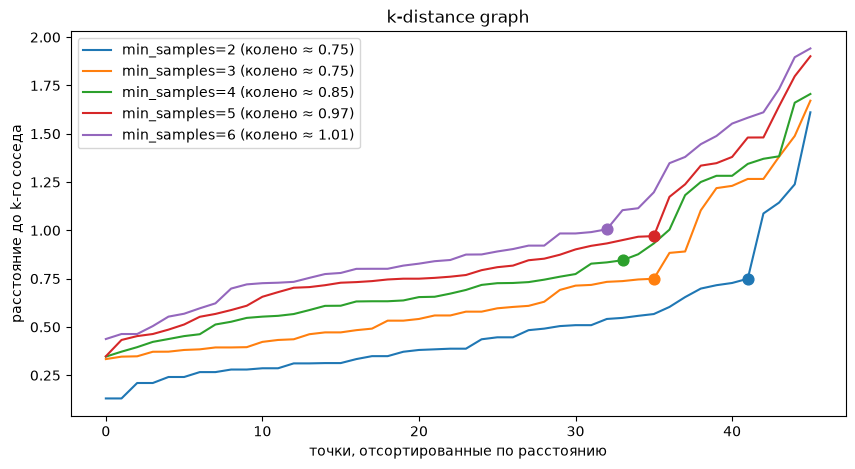

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
knee_eps = {}
for ms in [2, 3, 4, 5, 6]:
    nn = NearestNeighbors(n_neighbors=ms).fit(X_scaled)
    dist, _ = nn.kneighbors(X_scaled)
    d = np.sort(dist[:, -1])

    xs = np.arange(len(d)); p1, p2 = np.array([0, d[0]]), np.array([len(d) - 1, d[-1]])
    v, w = p2 - p1, np.c_[xs, d] - p1
    dev = np.abs(v[0] * w[:, 1] - v[1] * w[:, 0]) / np.linalg.norm(v)
    knee_eps[ms] = d[dev.argmax()]
    ax.plot(d, label=f"min_samples={ms} (колено ≈ {knee_eps[ms]:.2f})")
    ax.scatter(dev.argmax(), knee_eps[ms], s=60, zorder=5)
ax.set_xlabel("точки, отсортированные по расстоянию"); ax.set_ylabel("расстояние до k-го соседа")
ax.set_title("k-distance graph"); ax.legend(); plt.show()

При помощи данного графика можно сделать выводы, что лучше перебирать данные для *лучшей* модели будут : min_samples от 2 до 4, eps от 0.75 до 0.85
<br> А если лучшие, то min_samples = 2, eps = 0.75 или min_samples = 3, eps = 0.75

Проверим теорию, на практике, берем eps, min_samples и посмотрим на метрики шума, количества кластеров и силуэт

In [9]:
EPS = np.round(np.arange(0.65, 1.3, 0.05), 2)
MS = [2, 3, 4, 5, 6]

rows = []
for eps in EPS:
    for ms in MS:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        noise = np.mean(lab == -1)
        mask = lab != -1
        sil = silhouette_score(X_scaled[mask], lab[mask]) if n_cl >= 2 and mask.sum() > n_cl else np.nan
        rows.append({"eps": eps, "min_samples": ms, "n_clusters": n_cl, "noise_frac": noise, "silhouette": sil})
grid = pd.DataFrame(rows)


Оставим только те случаи, что шумовых точек меньше 20%, силуэт больше 0.3, а кластеров больше 2 (иначе будет "бедные-богатые")

In [10]:
grid[(grid["n_clusters"]  > 2) & (grid["noise_frac"] < 0.2) & (grid["silhouette"] > 0.3)]

,eps,min_samples,n_clusters,noise_frac,silhouette
0,0.65,2,4,0.195652,0.509198
5,0.70,2,4,0.152174,0.495650
10,0.75,2,4,0.086957,0.458661
15,0.80,2,4,0.086957,0.458661
20,0.85,2,3,0.086957,0.321871
25,0.90,2,3,0.086957,0.321871
30,0.95,2,3,0.086957,0.321871
35,1.00,2,3,0.086957,0.321871
40,1.05,2,3,0.086957,0.321871
45,1.10,2,3,0.065217,0.300491


Наше теоретическое значение min_samples = 2, eps = 0.75 попало в выборку

Посмотрим графики зависимости числа кластеров и долю шума от eps

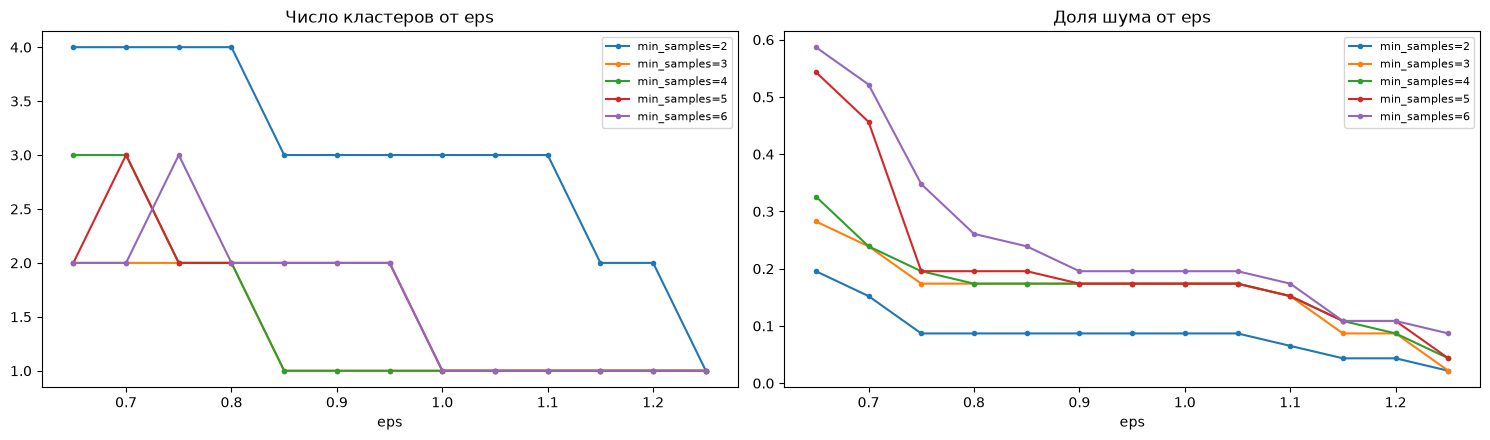

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ms in MS:
    g = grid[grid.min_samples == ms]
    axes[0].plot(g.eps, g.n_clusters, "o-", ms=3, label=f"min_samples={ms}")
    axes[1].plot(g.eps, g.noise_frac, "o-", ms=3, label=f"min_samples={ms}")
axes[0].set_title("Число кластеров от eps"); axes[1].set_title("Доля шума от eps")
for ax in axes: ax.set_xlabel("eps"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Вывод: # 
С увеличением eps число кластеров обычно падает и доля шума тоже

In [12]:
EPS , MS = 0.75, 2

dbscan = DBSCAN(eps=EPS, min_samples=MS).fit(X_scaled)

labels = dbscan.labels_
df["cluster"] = labels
ids, centers_orig = cluster_centers(X, labels)
m = labels != -1
print(f"eps={EPS}, min_samples={MS} | кластеров: {len(ids)}, шум: {(~m).sum()} "
      f"({(~m).mean():.0%}) | silhouette = {silhouette_score(X_scaled[m], labels[m]):.3f}")

eps=0.75, min_samples=2 | кластеров: 4, шум: 4 (9%) | silhouette = 0.459


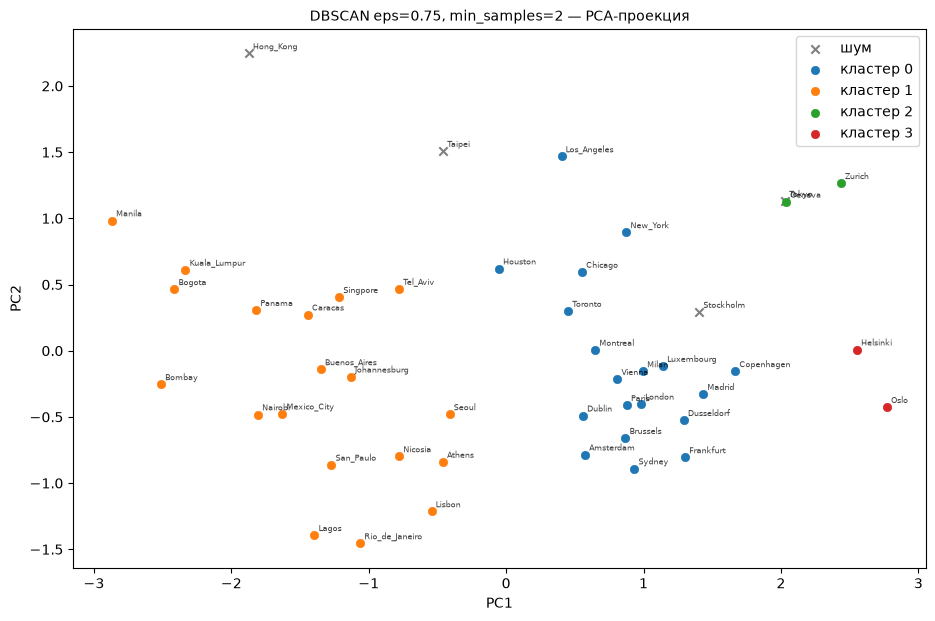

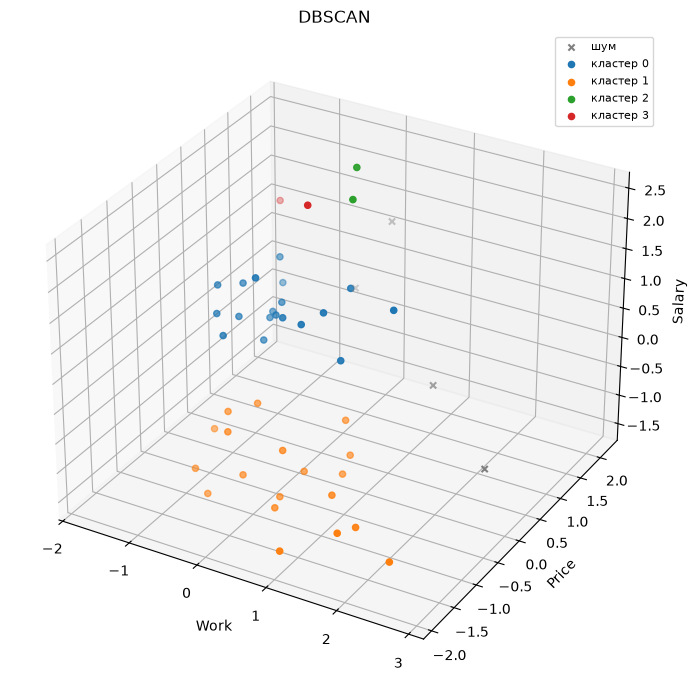

In [17]:
fig, ax = plt.subplots(figsize=(11, 7))
ids_s, cen_s = cluster_centers(X_scaled, labels)
plot_clusters_2d(ax, X_pca, labels, pca.transform(cen_s),
                 title=f"DBSCAN eps={EPS}, min_samples={MS} — PCA-проекция",
                 cities=df["City"].values)
ax.set_xlabel(f"PC1")
ax.set_ylabel(f"PC2")
ax.legend(); plt.show()

plot_3d(labels, centers_orig, f"DBSCAN")

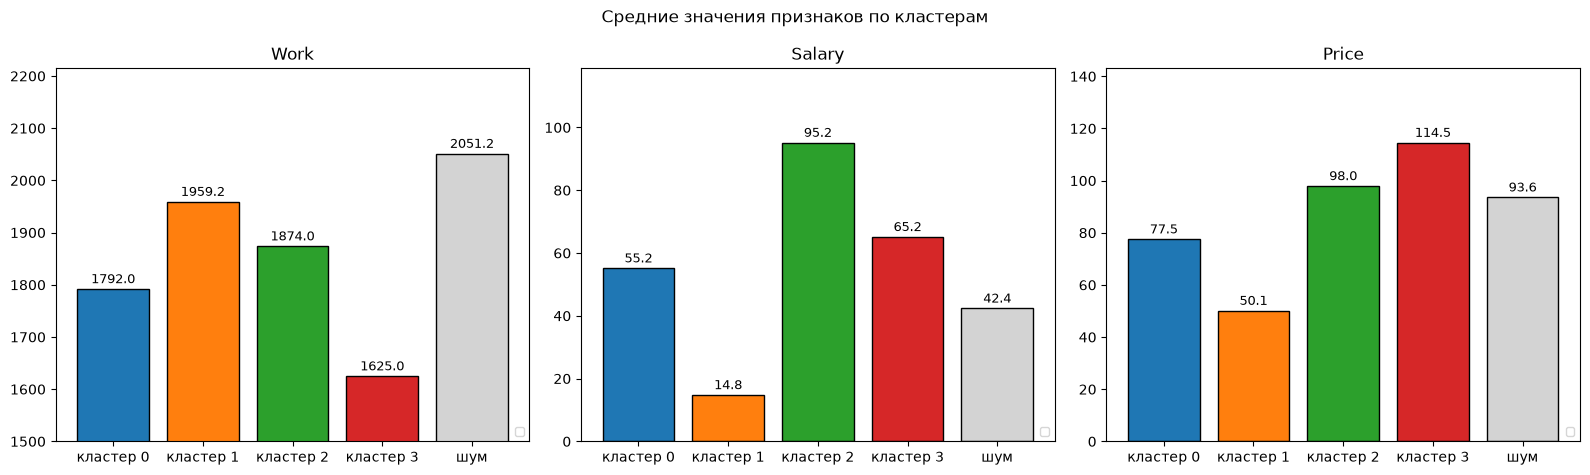

In [18]:
groups = list(ids) + [-1]
names = [f"кластер {c}" for c in ids] + ["шум"]
COLORS = plt.get_cmap("tab10")
colors = [COLORS(c) for c in ids] + ["lightgrey"]
means = df.groupby("cluster")[["Work", "Salary", "Price"]].mean().loc[groups]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, f in zip(axes, ["Work", "Salary", "Price"]):
    bars = ax.bar(names, means[f], color=colors, edgecolor="k")
    for b, v in zip(bars, means[f]):
        ax.annotate(f"{v:.1f}", (b.get_x() + b.get_width() / 2, v),
                    ha="center", va="bottom", fontsize=9, xytext=(0, 2), textcoords="offset points")
    ax.set_ylim(0, means[f].max() * 1.25)
    ax.set_title(f); ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylim(1500, means["Work"].max() * 1.08)
plt.suptitle("Средние значения признаков по кластерам")
plt.tight_layout(); plt.show()

In [19]:
profile = df.groupby("cluster")[["Work", "Salary", "Price"]].mean().round(1)
profile["число городов"] = df["cluster"].value_counts().sort_index()
profile["города"] = [", ".join(df.loc[df["cluster"] == c, "City"]) for c in profile.index]
profile = profile.rename(index={-1: "шум"})
pd.set_option("display.max_colwidth", None)
profile

,Work,Salary,Price,число городов,города
cluster,,,,,
шум,2051.2,42.4,93.6,4,"Hong_Kong, Stockholm, Taipei, Tokyo"
0,1792.0,55.2,77.5,19,"Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Paris, Sydney, Toronto, Vienna"
1,1959.2,14.8,50.1,19,"Athens, Bogota, Bombay, Buenos_Aires, Caracas, Johannesburg, Kuala_Lumpur, Lagos, Lisbon, Manila, Mexico_City, Nairobi, Nicosia, Panama, Rio_de_Janeiro, San_Paulo, Seoul, Singpore, Tel_Aviv"
2,1874.0,95.2,98.0,2,"Geneva, Zurich"
3,1625.0,65.2,114.6,2,"Helsinki, Oslo"


## Выводы

- **Кластер 0 — крупные города развитых стран** (Западная Европа, США, Канада, Сидней).
  Низкое количество рабочих часов, ниже зарплаты по сравнению с кластерами 2 - 3, но при этом цены ниже, чем у них (отклонение зарплата - цены около 22 пунктов) 
- **Кластер 1 — города развивающихся стран и юга Европы** (Афины, Лиссабон, Никосия, Сеул,
  Мехико, Буэнос-Айрес, Рио-де-Жанейро, Сан-Паулу, Йоханнесбург, Найроби, Лагос).
  Самое большое количество рабочих часов, но при этом низкие зарплаты, (отклонение зарплата - цены около 40 пунктов)
- **Кластер 2 — швейцарская идиллия** (Цюрих и Женева)
 Здесь заметно то, что самые высокие зарплаты, при этом больше рабочих часов, чем в остальной Европе, при этом отклонение зарплата - цены всего 3 пункта

- **Кластер 3 - суровая Скандинавия** (Хельсинки и Осло)
Здесь самые высокие цены , больше чем у остальных, отклонение зарплата - цены около 50 пунктов! Единственное, что лучше - меньше рабочая неделя


eps=0.85, min_samples=2 | кластеров: 3, шум: 4 (9%) | silhouette = 0.322


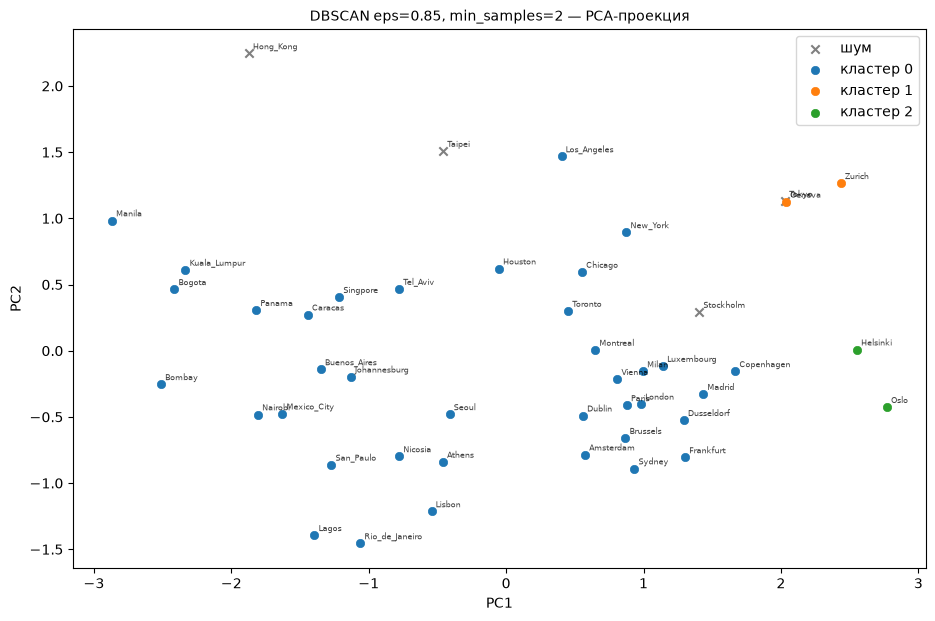

In [20]:
EPS , MS = 0.85, 2

dbscan = DBSCAN(eps=EPS, min_samples=MS).fit(X_scaled)

labels = dbscan.labels_
df["cluster"] = labels
ids, centers_orig = cluster_centers(X, labels)
m = labels != -1
print(f"eps={EPS}, min_samples={MS} | кластеров: {len(ids)}, шум: {(~m).sum()} "
      f"({(~m).mean():.0%}) | silhouette = {silhouette_score(X_scaled[m], labels[m]):.3f}")

fig, ax = plt.subplots(figsize=(11, 7))
ids_s, cen_s = cluster_centers(X_scaled, labels)
plot_clusters_2d(ax, X_pca, labels, pca.transform(cen_s),
                 title=f"DBSCAN eps={EPS}, min_samples={MS} — PCA-проекция",
                 cities=df["City"].values)
ax.set_xlabel(f"PC1")
ax.set_ylabel(f"PC2")
ax.legend(); plt.show()

eps=0.75, min_samples=3 | кластеров: 2, шум: 8 (17%) | silhouette = 0.512


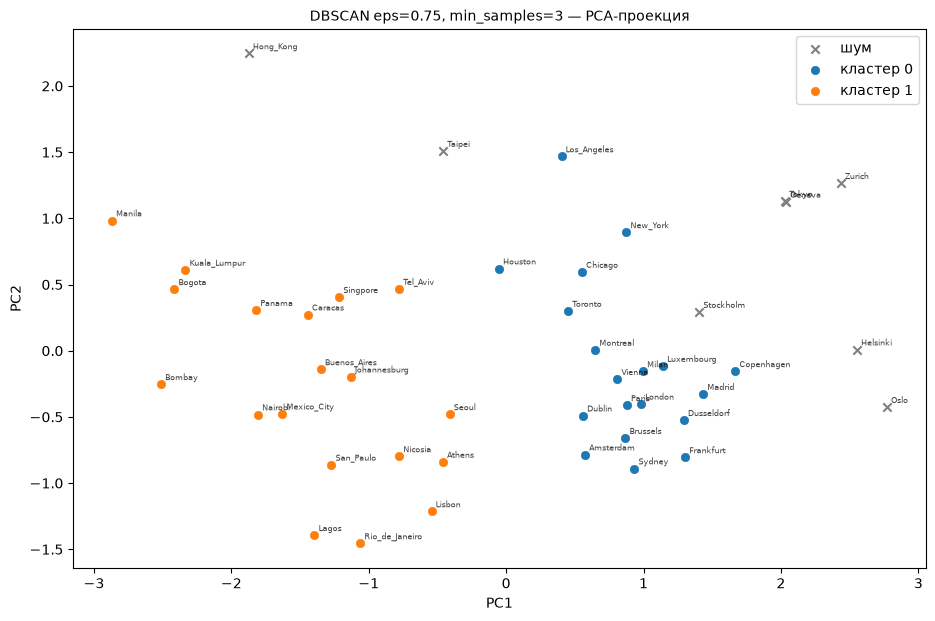

In [21]:
EPS , MS = 0.75, 3

dbscan = DBSCAN(eps=EPS, min_samples=MS).fit(X_scaled)

labels = dbscan.labels_
df["cluster"] = labels
ids, centers_orig = cluster_centers(X, labels)
m = labels != -1
print(f"eps={EPS}, min_samples={MS} | кластеров: {len(ids)}, шум: {(~m).sum()} "
      f"({(~m).mean():.0%}) | silhouette = {silhouette_score(X_scaled[m], labels[m]):.3f}")

fig, ax = plt.subplots(figsize=(11, 7))
ids_s, cen_s = cluster_centers(X_scaled, labels)
plot_clusters_2d(ax, X_pca, labels, pca.transform(cen_s),
                 title=f"DBSCAN eps={EPS}, min_samples={MS} — PCA-проекция",
                 cities=df["City"].values)
ax.set_xlabel(f"PC1")
ax.set_ylabel(f"PC2")
ax.legend(); plt.show()

Выше мы привели два доп эксперимента
<br> 1. Увеличили eps. Итог: 2 крупных кластера склеились
<br> 2. Увеличили min_samples. Итог: 2 кластера всего

# Общий вывод

Здесь получили при помощи перебора параметров нашли оптимальные параметры, при отхождении от которых результаты уже состоят из очень больших кластеров или из всего 2 кластеров
Интерпретация более тонкая, но рабочая, выделились мелкие, но яркие кластеры